Every autumn Portuguese newspapers publish the ranking of secondary schools by performance in the national exams. The 2026 edition, assembled from the JNE tables by the Correio da Manhã datajournalism desk, lists 651 schools together with their average exam grade. The list invites a specific way of reading: a school at position 5 is *better* than a school at position 50, by an amount the reader is never shown. This post is about the difference between those two quantities, the position and the grade, and why the first hides the second. It is the first in a planned series on what the school ranking can and cannot tell you.

## A rank is not a distance

Ranks are an ordinal quantity: the only information in them is the order of pairwise comparisons, which school sits above which. The grade is a cardinal quantity: it carries a distance. Replacing the grade by a rank is harmless when the ranked quantity is well spread out and the units are far apart; it destroys information exactly where the distribution is dense. A league table built from a dense distribution does precisely this, and it does it throughout the table: two schools one position apart may differ by several grades, or by a fraction of one.

## One position, many different distances

Load the filtered table and look at the top of it. The consecutive gaps at the top are not variations around a common distance; they are different worlds. Between positions 1 and 2 there are 4.84 points (164.51 versus 159.67). Between positions 3 and 4 there are 1.17 points (155.28 versus 154.11). And around position 210, ten consecutive gaps altogether cover 0.29 points, less than the distance between positions 3 and 4 alone. Note that nothing is wrong with the ranking itself as arithmetic: the rule is applied consistently. What the rank difference cannot tell you is what the grade difference actually means in terms of grades.

In [7]:
#| echo: false

import pandas as pd

pd.read_csv("../../school_rankings_pt/cm_2026_geral.csv")

,rank,escola,concelho,n,media
0,1,Colégio St. Paul's School,Coimbra,1,178.00
1,2,Grande Colégio Universal,Porto,87,169.44
2,3,Colégio Internacional de Vilamoura,Loulé,20,164.75
3,4,Colégio Nossa Senhora do Rosário,Porto,277,164.51
4,5,Colégio Horizonte,Vila Nova de Gaia,20,161.70
...,...,...,...,...,...
646,647,Escola Monsenhor José Galamba de Oliveira,Leiria,10,66.30
647,648,"Escola Secundária da Baixa da Banheira, Vale d...",Moita,137,64.11
648,649,Instituto Vaz Serra,Sertã,108,61.54
649,650,Escola Básica Integrada Mouzinho da Silveira,Corvo,4,54.25


In [9]:
#| code-fold: true
#| echo: false

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Validated categorical palette (dataviz reference instance, slots 1-3).
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 120, "font.size": 9, "axes.titlesize": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "figure.facecolor": "white",
})

# The table is a local copy of the CM datajournalism page (see data note at the end);
# it lives in a private data repository, referenced here by relative path.
CANDIDATES = [
    Path("../projects/school_rankings_pt/cm_2026_geral.csv"),
    Path("../../school_rankings_pt/cm_2026_geral.csv"),
    Path("projects/school_rankings_pt/cm_2026_geral.csv"),
]
data_path = next(p for p in CANDIDATES if p.exists())

import csv

MIN_EXAMS = 100  # keep schools with more than this many exam sittings

def load(path, min_exams=MIN_EXAMS):
    rows = []
    with open(path, encoding="utf-8") as f:
        for r in csv.DictReader(f):
            rows.append((int(r["rank"]), r["escola"], r["concelho"], int(r["n"]), float(r["media"])))
    rows = [r for r in rows if r[3] > min_exams]
    rows.sort(key=lambda x: -x[4])
    return rows

rank_list = load(data_path)
ranks = np.arange(1, len(rank_list) + 1)
grades = np.array([r[4] for r in rank_list])

def grade(r, i=4):
    return rank_list[r - 1][i]

print(f"{len(rank_list)} schools with more than {MIN_EXAMS} exam sittings, "
      f"grades from {grades.min():.2f} to {grades.max():.2f} on the 0-200 scale")
for i in (1, 2, 3):
    g = grade(i) - grade(i + 1)
    print(f"gap between ranks {i} and {i+1}: {g:.2f} grades "
          f"({grade(i):.2f} vs {grade(i+1):.2f})")

431 schools with more than 100 exam sittings, grades from 61.54 to 164.51 on the 0-200 scale
gap between ranks 1 and 2: 4.84 grades (164.51 vs 159.67)
gap between ranks 2 and 3: 4.39 grades (159.67 vs 155.28)
gap between ranks 3 and 4: 1.17 grades (155.28 vs 154.11)


The same disproportion runs through the whole table, and it has a location: the compression concentrates where the distribution of average grades is dense, around the middle. Half a grade around the median of 101.95 buys about 13 positions. The stretch from rank 210 to rank 219, ten consecutive gaps altogether, covers 0.29 grades. In the other direction, the largest gap in the filtered table is not at the top: 6.23 grades separate positions 429 and 430, near the bottom, where the schools thin out. And 19 pairs of consecutive schools share exactly the same average, their order decided by nothing the table reports.

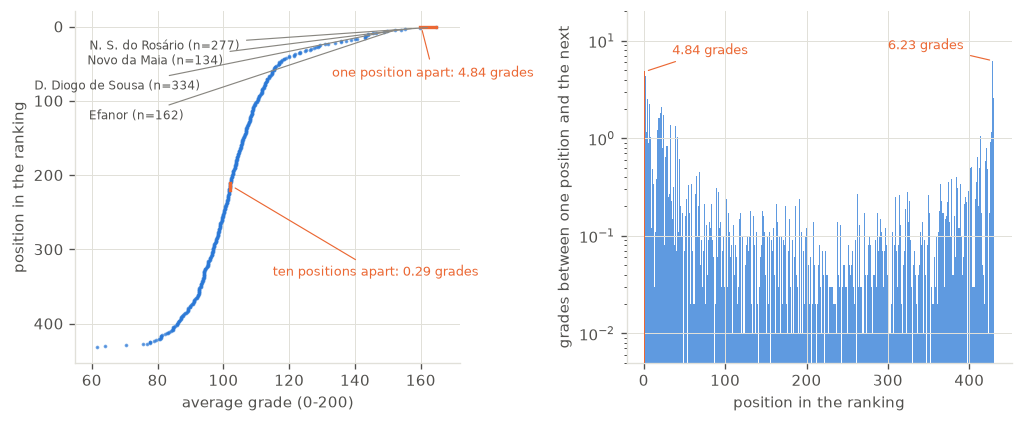

In [10]:
#| code-fold: true


# Position against grade, and the grade price of one consecutive position.
fig, (axA, axB) = plt.subplots(1, 2, figsize=(8.6, 3.6))

# Panel A: the staircase. Steep where schools are scarce, flat where they crowd.
axA.plot(grades, ranks, ".", color=BLUE, ms=2.5, alpha=0.6)
axA.invert_yaxis()
axA.set_xlim(55, 172)
axA.set_xlabel("average grade (0-200)")
axA.set_ylabel("position in the ranking")

# The one position that costs almost five grades.
g_top = grade(1) - grade(2)
axA.plot([grade(2), grade(1)], [1, 1], color=ORANGE, lw=2.0)
axA.annotate(f"one position apart: {g_top:.2f} grades",
             xy=(grade(2) + 0.5, 1), xytext=(133, 62), fontsize=7.5,
             color=ORANGE, ha="left", va="center",
             arrowprops=dict(arrowstyle="-", lw=0.7, color=ORANGE))

arrows = dict(arrowstyle="-", lw=0.7, color=MUTED)
labels = [("N. S. do Ros\u00e1rio (n=277)", 105, 26, grade(1) - 1.5, 1),
          ("Novo da Maia (n=134)", 100, 46, grade(2) - 1.5, 2),
          ("D. Diogo de Sousa (n=334)", 93, 80, grade(3) - 1.5, 3),
          ("Efanor (n=162)", 88, 120, grade(4) - 1.5, 4)]
for text, tx, ty, px, py in labels:
    axA.annotate(text, (px, py), xytext=(tx, ty), fontsize=7, color=INK2,
                 ha="right", va="center", arrowprops=arrows)

# The ten gaps that cost a fraction of a grade altogether.
spans = grades[: -10] - grades[10:]
j = int(np.argmin(spans))
lo_rank = int(ranks[j])
axA.plot([grades[j], grades[j]], [lo_rank, lo_rank + 10], color=ORANGE, lw=2.0)
axA.annotate(f"ten positions apart: {spans[j]:.2f} grades", xy=(grades[j] + 0.6, lo_rank + 5),
             xytext=(115, 330), fontsize=7.5,
             color=ORANGE, ha="left", va="center",
             arrowprops=dict(arrowstyle="-", lw=0.7, color=ORANGE))

# Panel B: what one position costs across the whole table (log scale).
gaps = -np.diff(grades)
axB.bar(ranks[:-1], gaps, width=1.0, color=BLUE, alpha=0.75)
axB.bar(1, gaps[0], width=1.0, color=ORANGE, zorder=5)
axB.set_yscale("log")
axB.set_ylim(5e-3, 20)
axB.set_xlabel("position in the ranking")
axB.set_ylabel("grades between one position and the next")
axB.annotate("4.84 points", xy=(1.8, gaps[0]),
             xytext=(35, 8), fontsize=7.5, color=ORANGE, ha="left", va="center",
             arrowprops=dict(arrowstyle="-", lw=0.7, color=ORANGE))
k = int(np.argmax(gaps))
axB.annotate("6.23 points", xy=(ranks[k], gaps[k]),
             xytext=(300, 9), fontsize=7.5, color=ORANGE, ha="left", va="center",
             arrowprops=dict(arrowstyle="-", lw=0.7, color=ORANGE))

fig.tight_layout()

## Where the compression lives

Figure 1 makes the point in two views of the same arithmetic. On the left, position against grade traces a staircase: steep at the top, where schools are scarce, and essentially flat in the middle, where dozens of schools share nearly the same average. On the right, each bar is the underlying grade gap of one consecutive position in the table, on a log scale: the 4.84 grades separating positions 1 and 2 and the gaps of a few hundredths of a grade in the middle are the same unit of the table, one position. Note that the ordination itself is beyond dispute in both regions; what changes by orders of magnitude is what one unit of the table is worth in the quantity that produced it.

This is the sense in which a rank is not a size. Any sentence built on rank differences, *close in the ranking*, *far ahead of*, *a dozen positions behind*, is silent about magnitude, and the underlying distribution supplies magnitudes that differ by a factor of nearly 500 between one stretch of the table and another. The fix is not to abandon rankings; it is to remember that the table answers *who is above whom* and never *by how much*.

## Take-home

- A ranking is an ordinal statement; the grades behind it are cardinal. Compressing one into the other discards magnitude, and the loss is not uniform.
- In the 2026 table restricted to schools with more than 100 exam sittings, one position costs 4.84 grades at the top and 0.01 grades in the middle; ten consecutive positions around rank 210 span 0.29 grades in total, and 27 schools sit within a single grade around the median.
- Positions compare, grades measure. Before reading a league table as a scale of quality, read the grades.

**Data and code note.** The table used here is the 2026 school ranking from the Correio da Manhã datajournalism pages ([results/2026/1](https://www.cmjornal.pt/datajournalism/schoolresults/results/2026/1)), a republication of the Ministério da Educação / JNE national exam results (exams sat in June 2026, school year 2025/26); grades are school averages on the 0-200 scale, and the number of exam sittings per school is given alongside. The analysis keeps schools with more than 100 exam sittings, 431 of the 651 listed; the filter and its sensitivity to the cutoff are discussed in Section 2. The working copy is in a private data repository, assembled with documentation of the source tables and their quirks; the computations in this post run on that copy.